**Set environment**

In [1]:
%run ../run_config_project_sing.py
config.show_env()

You are working on        Singularity: singularity_proj_encode_fcc
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data


You are working with      ENCODE FCC
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references



In [3]:
import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import sys, os

import umap
import phenograph

## Import data

**Check data**

In [6]:
config.FD_RES

'/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results'

In [8]:
txt_fdiry = os.path.join(
    config.FD_RES, 
    "analysis_umap_cluster_by_coverage", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "prepare_matrix"
)
lst = os.listdir(txt_fdiry)
for txt in lst:
    print(txt)

matrix.coverage.encode_chipseq_full_log2p.tsv
.ipynb_checkpoints


**Import data**

In [9]:
### set file directory
txt_fdiry = os.path.join(
    config.FD_RES, 
    "analysis_umap_cluster_by_coverage", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "prepare_matrix"
)
txt_fname = "matrix.coverage.encode_chipseq_full_log2p.tsv"
txt_fpath = os.path.join(txt_fdiry, txt_fname)

### read table
mat = pd.read_csv(txt_fpath, sep = "\t")
vec = mat.Region
mat = mat.set_index('Region')

### assign and show
mat_region_score = mat
print(mat.shape)
mat.head()

(33953, 522)


,H2AFZ,H3K27ac,H3K27me3,H3K36me3,H3K4me1,H3K4me2,H3K4me3,H3K79me2,H3K9ac,H3K9me1,...,ZNF780A,ZNF785,ZNF79,ZNF7,ZNF830,ZNF83,ZNF84,ZSCAN29,ZSCAN32,ZZZ3
Region,,,,,,,,,,,,,,,,,,,,,
chr1:605104-605675,2.094986,0.920123,0.095492,0.000000,1.624363,1.560025,0.944592,0.147714,1.314610,0.000000,...,0.658671,0.718087,0.770129,1.097442,0.885336,1.140962,0.912170,1.148158,0.850398,1.069310
chr1:778233-779389,3.119901,3.174314,0.392439,0.865637,1.147726,3.991318,4.828437,2.302933,3.739369,0.272737,...,0.720876,0.747710,1.277931,1.507932,0.692684,0.920362,1.332811,1.112834,1.107500,0.973985
chr1:818708-819335,1.074821,1.156811,0.494213,1.765193,1.115060,1.075847,0.514251,0.842589,1.258866,1.796864,...,0.642015,0.346657,0.197374,0.648049,0.406663,0.828134,0.502830,0.332551,0.221626,0.685762
chr1:826796-828040,3.028686,3.123304,0.234842,0.498363,0.952056,4.076243,4.631593,1.968950,3.798574,0.647794,...,0.458223,0.419271,0.427725,0.894756,0.583278,0.869898,0.733878,2.411239,0.767962,0.607506
chr1:842516-843431,1.222347,1.351951,0.471345,1.453915,2.348405,3.213781,1.375006,1.473808,1.795823,2.046854,...,1.128313,0.774432,0.511727,1.615237,0.697273,0.708501,0.921243,1.096289,0.790368,0.926633


In [23]:
dat = mat_region_score
communities, graph, Q = phenograph.cluster(dat, k = 100)

Finding 100 nearest neighbors using minkowski metric and 'auto' algorithm
Neighbors computed in 5.24639105796814 seconds
Jaccard graph constructed in 17.791681051254272 seconds
Wrote graph to binary file in 1.569103479385376 seconds
Running Louvain modularity optimization
After 1 runs, maximum modularity is Q = 0.746758
After 11 runs, maximum modularity is Q = 0.74872
Louvain completed 31 runs in 68.04576802253723 seconds
Sorting communities by size, please wait ...
PhenoGraph completed in 93.82840943336487 seconds


In [24]:
# convert coo_matrix to igraph
sources, targets = graph.nonzero()
g = ig.Graph(list(zip(sources, targets)), directed=False)
g.es["weight"] = graph.data.tolist()

# number of connected components
comps = g.components()
print("Connected components:", len(comps))
print("Largest component size:", max(len(c) for c in comps))

# degree distribution
deg = g.degree()
print("Degree: mean", np.mean(deg), "min", np.min(deg), "max", np.max(deg))

# edge weights
wts = g.es["weight"]
print("Edge weights: mean", np.mean(wts), "min", np.min(wts), "max", np.max(wts))

Connected components: 1
Largest component size: 33953
Degree: mean 175.41860807586957 min 94 max 2343
Edge weights: mean 0.10459186887779696 min 0.002512562814070352 max 0.941747572815534


In [25]:
sizes = pd.Series(communities).value_counts().sort_index()
print("Number of clusters:", sizes.shape[0])
print("Smallest cluster size:", sizes.min())
print("Largest cluster size:", sizes.max())

Number of clusters: 15
Smallest cluster size: 41
Largest cluster size: 7254


## Run clustering

In [10]:
dat = mat_region_score
communities, graph, Q = phenograph.cluster(dat, k = 70)

Finding 70 nearest neighbors using minkowski metric and 'auto' algorithm
Neighbors computed in 5.570926189422607 seconds
Jaccard graph constructed in 11.309789657592773 seconds
Wrote graph to binary file in 1.12211012840271 seconds
Running Louvain modularity optimization
After 1 runs, maximum modularity is Q = 0.757363
After 2 runs, maximum modularity is Q = 0.758662
After 18 runs, maximum modularity is Q = 0.759775
After 37 runs, maximum modularity is Q = 0.761185
Louvain completed 57 runs in 89.53737378120422 seconds
Sorting communities by size, please wait ...
PhenoGraph completed in 108.50750494003296 seconds


## Diagnose the graph/partition

A. Diagnose the graph/partition

Connectivity: ensure 1 connected component (or ≥99.5% of nodes in the giant component). Many tiny components → k too small or features not scaled.

Degree distribution: median degree should be near k (after symmetrization) with no big tail of degree≪k (isolates) → again suggests k too small or noisy features.

Edge weights: Jaccard weights should be right-skewed; if almost all edges are tiny, you’re over-connecting (k too large) or mixing unrelated regions.

In [11]:
graph

<33953x33953 sparse matrix of type '<class 'numpy.float64'>'
	with 2100939 stored elements in COOrdinate format>

In [12]:
# number of connected components
n_comp = len(graph.components())
print("Connected components:", n_comp)

AttributeError: 'coo_matrix' object has no attribute 'components'

In [13]:
import igraph as ig

In [17]:
# convert coo_matrix to igraph
sources, targets = graph.nonzero()
g = ig.Graph(list(zip(sources, targets)), directed=False)
g.es["weight"] = graph.data.tolist()

# number of connected components
comps = g.components()
print("Connected components:", len(comps))
print("Largest component size:", max(len(c) for c in comps))

# degree distribution
deg = g.degree()
print("Degree: mean", np.mean(deg), "min", np.min(deg), "max", np.max(deg))

# edge weights
wts = g.es["weight"]
print("Edge weights: mean", np.mean(wts), "min", np.min(wts), "max", np.max(wts))

Connected components: 1
Largest component size: 33953
Degree: mean 123.75572114393427 min 61 max 1932
Edge weights: mean 0.09691866526503898 min 0.0035971223021582736 max 0.8918918918918919


In [18]:
sizes = pd.Series(communities).value_counts().sort_index()
print("Number of clusters:", sizes.shape[0])
print("Smallest cluster size:", sizes.min())
print("Largest cluster size:", sizes.max())

Number of clusters: 18
Smallest cluster size: 57
Largest cluster size: 6817


In [19]:
labels = np.array(communities)
m = labels.max() + 1
W = np.zeros((m, m))

for e in g.es:
    a, b = labels[e.tuple[0]], labels[e.tuple[1]]
    if a != b:
        W[a, b] += e["weight"]
        W[b, a] += e["weight"]

sizes = np.bincount(labels)
Norm = W / (sizes[:, None] * sizes[None, :])

# Build igraph for the meta-graph
pairs = np.argwhere(np.triu(Norm, 1) > 0)
H = ig.Graph()
H.add_vertices(m)
H.add_edges([tuple(p) for p in pairs])
H.es["weight"] = [Norm[i, j] for i, j in pairs]

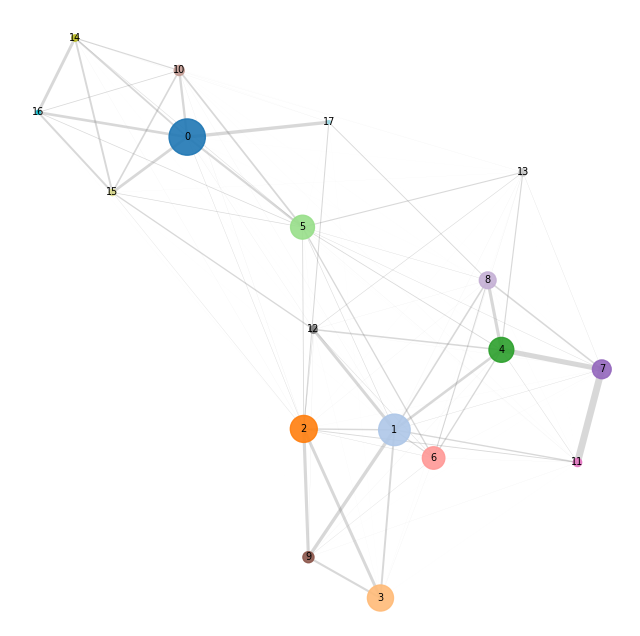

In [22]:
layout = np.array(H.layout_fruchterman_reingold(weights=H.es["weight"]))

fig, ax = plt.subplots(figsize=(8,8))

# rescale edge weights for visibility
wts = np.array(H.es["weight"])
wts = (wts / wts.max()) * 5.0  # scale 0–5

# draw edges
for e, w in zip(H.es, wts):
    src, tgt = e.tuple
    x1, y1 = layout[src]
    x2, y2 = layout[tgt]
    ax.plot([x1, x2], [y1, y2],
            linewidth=w, alpha=0.3, color="gray", zorder=1)

# draw nodes
node_sizes = [s/10 for s in sizes]  # rescale to look good
sc = ax.scatter(layout[:,0], layout[:,1],
                s=node_sizes,
                c=range(H.vcount()), cmap="tab20", alpha=0.9, zorder=2)

# add labels
for i, (x, y) in enumerate(layout):
    ax.text(x, y, str(i), fontsize=7, ha="center", va="center", zorder=3)

ax.axis("off")
plt.show()

In [1]:
import numpy  as np
import pandas as pd
import matplotlib.pyplot as plt
import sys, os

import umap
import phenograph

import importlib.util
def import_from_file(module_name, file_path):
    spec   = importlib.util.spec_from_file_location(module_name, file_path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

CONFIG = import_from_file('config', '../run_config_project_sing.py')
CONFIG.show_env()

You are working on        Singularity: singularity_proj_encode_fcc
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data


You are working with      ENCODE FCC
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references



In [2]:
CONFIG.FD_REPO

'/data/reddylab/Kuei/repo'

In [3]:
CONFIG.FD_PRJ

'/data/reddylab/Kuei/repo/Proj_ENCODE_FCC'

## Import data

In [4]:
txt_fdiry = os.path.join(
    CONFIG.FD_RES, 
    "analysis_umap_cluster_by_coverage_score", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "prepare_matrix"
)
lst = os.listdir(txt_fdiry)
for txt in lst:
    print(txt)

matrix.coverage.encode_chipseq_full_log2p.tsv
matrix.coverage.encode_chipseq_full_mean0.tsv
matrix.coverage.encode_chipseq_full_zscore.fcc_zscore.tss.tsv
matrix.coverage.encode_chipseq_full_zscore.fcc_zscore.tsv
matrix.coverage.encode_chipseq_full_zscore.tsv
matrix.coverage.fcc_zscore.tsv


In [5]:
txt_fdiry = os.path.join(
    CONFIG.FD_RES, 
    "analysis_umap_cluster_by_coverage_score", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "prepare_matrix"
)
txt_fname = "matrix.coverage.encode_chipseq_full_log2p.tsv"
txt_fpath = os.path.join(txt_fdiry, txt_fname)

mat = pd.read_csv(txt_fpath, sep="\t")
vec = mat.Region
mat = mat.set_index('Region')

mat_region_score = mat
print(mat.shape)
mat.head()

(18341, 521)


,H2AFZ,H3K27ac,H3K27me3,H3K36me3,H3K4me1,H3K4me2,H3K4me3,H3K79me2,H3K9ac,H3K9me1,...,ZNF778,ZNF780A,ZNF785,ZNF79,ZNF83,ZNF830,ZNF84,ZSCAN29,ZSCAN32,ZZZ3
Region,,,,,,,,,,,,,,,,,,,,,
chr1:100036895-100039189,2.899574,3.910099,0.409154,1.197812,1.069881,4.947811,5.521968,4.177296,4.663171,0.943200,...,0.470371,0.997476,0.749405,0.784789,1.059418,0.900666,1.149806,1.249139,1.045114,1.033166
chr1:100132375-100133491,3.511342,3.432175,0.342399,0.766170,0.611599,4.537458,5.160366,2.783096,4.025729,0.882832,...,0.831960,0.813704,0.763733,1.342896,1.278580,0.983076,1.285402,1.344204,1.306595,1.304038
chr1:100265562-100266994,3.496910,3.284969,0.523121,1.064331,1.224565,4.710806,5.403491,3.499795,4.206733,0.852746,...,0.825408,1.127501,0.843342,1.326117,0.994073,0.907716,1.253039,1.217287,1.263143,1.129296
chr1:10032429-10033763,3.354819,3.412492,0.315848,0.590785,1.149366,4.590871,4.823100,2.317032,3.945846,0.718048,...,0.666777,0.929208,0.893152,1.037769,0.844770,0.911814,1.164059,1.228428,1.018435,0.911599
chr1:100362769-100363401,1.923438,3.315037,0.370305,0.853586,0.910019,3.980117,3.433015,3.114860,3.647725,1.196009,...,0.942585,1.296269,0.900235,1.557185,1.323606,0.899546,1.704624,0.968597,1.581804,1.040023


In [12]:
dat = mat_region_score
communities, graph, Q = phenograph.cluster(dat, k = 70)

Finding 70 nearest neighbors using minkowski metric and 'auto' algorithm
Neighbors computed in 1.0483372211456299 seconds
Jaccard graph constructed in 5.668705940246582 seconds
Wrote graph to binary file in 0.54984450340271 seconds
Running Louvain modularity optimization
After 1 runs, maximum modularity is Q = 0.718959
After 4 runs, maximum modularity is Q = 0.720574
Louvain completed 24 runs in 17.484044790267944 seconds
Sorting communities by size, please wait ...
PhenoGraph completed in 25.605312824249268 seconds


In [17]:
print(len(communities))
communities

18341


array([0, 0, 0, ..., 9, 3, 0])

In [18]:
graph

<18341x18341 sparse matrix of type '<class 'numpy.float64'>'
	with 1111252 stored elements in COOrdinate format>

In [19]:
dat = pd.DataFrame(communities, columns=["Cluster"])
dat = dat.assign(Region = vec)
dat

,Cluster,Region
0,0,chr1:100036895-100039189
1,0,chr1:100132375-100133491
2,0,chr1:100265562-100266994
3,13,chr1:10032429-10033763
4,0,chr1:100362769-100363401
...,...,...
18336,7,chrX:9351677-9353363
18337,3,chrX:95903401-95903802
18338,9,chrX:9786386-9786821
18339,3,chrX:9882663-9883076


In [20]:
txt_fdiry = os.path.join(
    CONFIG.FD_RES, 
    "analysis_umap_cluster_by_coverage_score", 
    "fcc_astarr_macs_input_overlap",
    "fcc_starrmpracrispri_vote2",
    "cluster_phenograph"
)
txt_fname = "cluster.neighbors_070.coverage.encode_chipseq_full_log2p.tsv"
txt_fpath = os.path.join(txt_fdiry, txt_fname)

dat.to_csv(txt_fpath, sep="\t", index=False)